In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC, SVR
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.ensemble import AdaBoostClassifier, AdaBoostRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

from pathlib import Path
import json, sklearn

# Paths are relative to this notebook (notebooks/). Data lives in ../data, the model is saved to ../model.
DATA_PATH = Path("../data/heart_cleveland_upload.csv")
MODEL_DIR = Path("../model")
MODEL_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
df = pd.read_csv(DATA_PATH)

In [3]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,condition
0,69,1,0,160,234,1,2,131,0,0.1,1,1,0,0
1,69,0,0,140,239,0,0,151,0,1.8,0,2,0,0
2,66,0,0,150,226,0,0,114,0,2.6,2,0,0,0
3,65,1,0,138,282,1,2,174,0,1.4,1,1,0,1
4,64,1,0,110,211,0,2,144,1,1.8,1,0,0,0


In [4]:
df.dtypes

age            int64
sex            int64
cp             int64
trestbps       int64
chol           int64
fbs            int64
restecg        int64
thalach        int64
exang          int64
oldpeak      float64
slope          int64
ca             int64
thal           int64
condition      int64
dtype: object

In [5]:
df.shape

(297, 14)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        297 non-null    int64  
 1   sex        297 non-null    int64  
 2   cp         297 non-null    int64  
 3   trestbps   297 non-null    int64  
 4   chol       297 non-null    int64  
 5   fbs        297 non-null    int64  
 6   restecg    297 non-null    int64  
 7   thalach    297 non-null    int64  
 8   exang      297 non-null    int64  
 9   oldpeak    297 non-null    float64
 10  slope      297 non-null    int64  
 11  ca         297 non-null    int64  
 12  thal       297 non-null    int64  
 13  condition  297 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 32.6 KB


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,297.0,54.542088,9.049736,29.0,48.0,56.0,61.0,77.0
sex,297.0,0.676768,0.468500,0.0,0.0,1.0,1.0,1.0
cp,297.0,2.158249,0.964859,0.0,2.0,2.0,3.0,3.0
trestbps,297.0,131.693603,17.762806,94.0,120.0,130.0,140.0,200.0
chol,297.0,247.350168,51.997583,126.0,211.0,243.0,276.0,564.0
fbs,297.0,0.144781,0.352474,0.0,0.0,0.0,0.0,1.0
restecg,297.0,0.996633,0.994914,0.0,0.0,1.0,2.0,2.0
thalach,297.0,149.599327,22.941562,71.0,133.0,153.0,166.0,202.0
exang,297.0,0.326599,0.469761,0.0,0.0,0.0,1.0,1.0
oldpeak,297.0,1.055556,1.166123,0.0,0.0,0.8,1.6,6.2


In [8]:
df['condition'].value_counts()


condition
0    160
1    137
Name: count, dtype: int64

In [9]:
df['condition'].value_counts(normalize=True) * 100


condition
0    53.872054
1    46.127946
Name: proportion, dtype: float64

In [10]:
df.groupby('condition')[['age','chol','trestbps','thalach']].mean()


,age,chol,trestbps,thalach
condition,,,,
0,52.643750,243.493750,129.175000,158.581250
1,56.759124,251.854015,134.635036,139.109489


In [11]:
df['cp'].value_counts()


cp
3    142
2     83
1     49
0     23
Name: count, dtype: int64

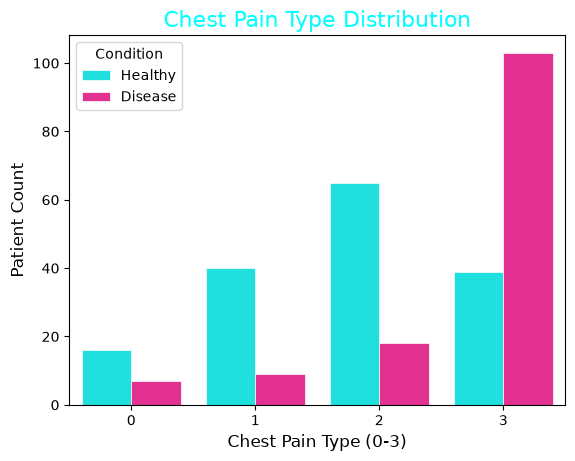

In [12]:
vibrant_colors = ['#00FFFF', '#FF1493'] 
sns.set_palette(vibrant_colors)
sns.countplot(data=df, x='cp', hue='condition', edgecolor='white', linewidth=0.5)
plt.title('Chest Pain Type Distribution', fontsize=16, color='#00FFFF')
plt.xlabel('Chest Pain Type (0-3)', fontsize=12)
plt.ylabel('Patient Count', fontsize=12)
plt.legend(title='Condition', labels=['Healthy', 'Disease'])

plt.show()

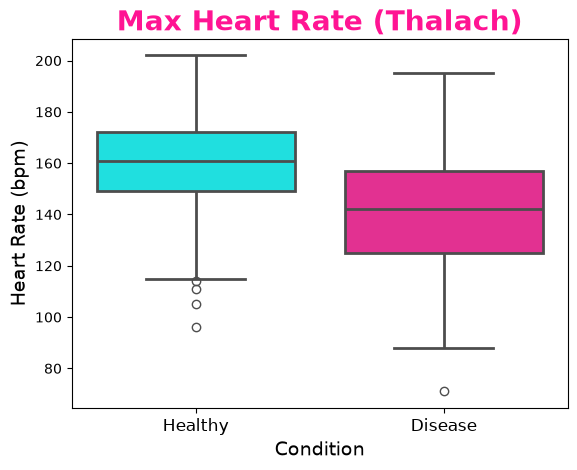

In [13]:
sns.boxplot(data=df, x='condition', y='thalach', palette=vibrant_colors, linewidth=2)

plt.title('Max Heart Rate (Thalach)', fontsize=20, color='#FF1493', weight='bold')
plt.xlabel('Condition', fontsize=14)
plt.ylabel('Heart Rate (bpm)', fontsize=14)
plt.xticks([0, 1], ['Healthy', 'Disease'], fontsize=12)

plt.show()

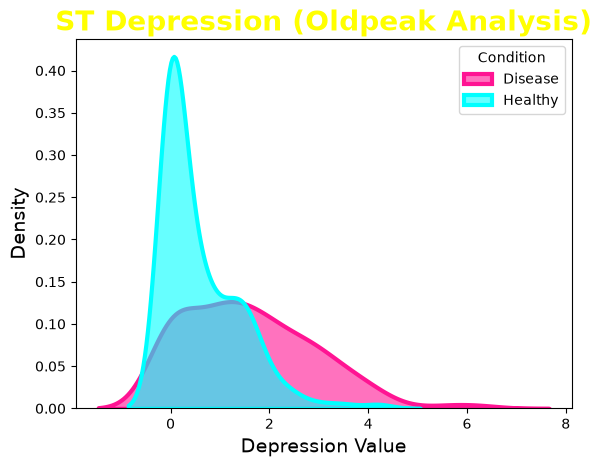

In [14]:
sns.kdeplot(data=df, x='oldpeak', hue='condition', fill=True, palette=vibrant_colors, alpha=0.6, linewidth=3)

plt.title('ST Depression (Oldpeak Analysis)', fontsize=20, color='#FFFF00', weight='bold')
plt.xlabel('Depression Value', fontsize=14)
plt.ylabel('Density', fontsize=14)
plt.legend(title='Condition', labels=['Disease', 'Healthy'])

plt.show()

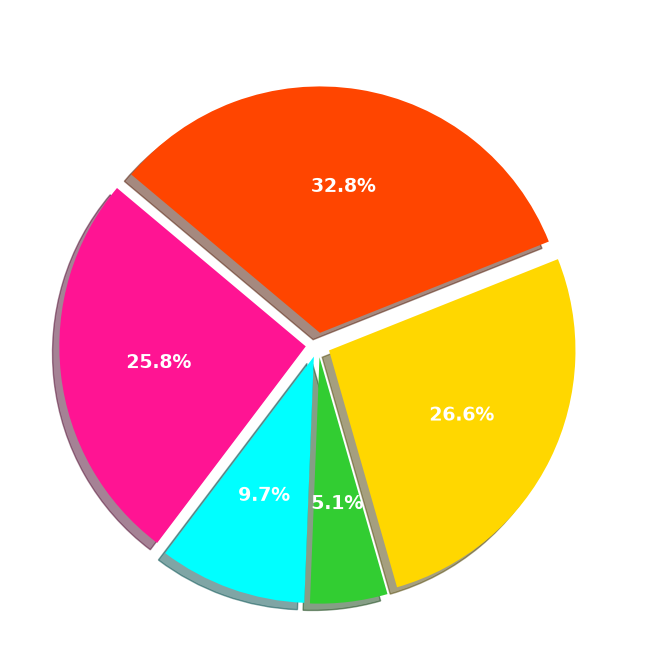

In [15]:
features = ['cp', 'trestbps', 'chol', 'exang', 'thal']
impact = df[features].corrwith(df['condition']).abs()
cyber_colors = ['#FF1493', '#00FFFF', '#32CD32', '#FFD700', '#FF4500', '#9400D3']
plt.figure(figsize=(8, 8))
explode = [0.05] * len(features) 

plt.pie(impact, labels=features,colors=cyber_colors, autopct='%1.1f%%',explode=explode,shadow=True,startangle=140,
textprops={'fontsize': 14, 'color': 'white', 'weight': 'bold'})

plt.title('Feature Impact on Heart Disease', fontsize=18, color='white', weight='bold')
plt.show()

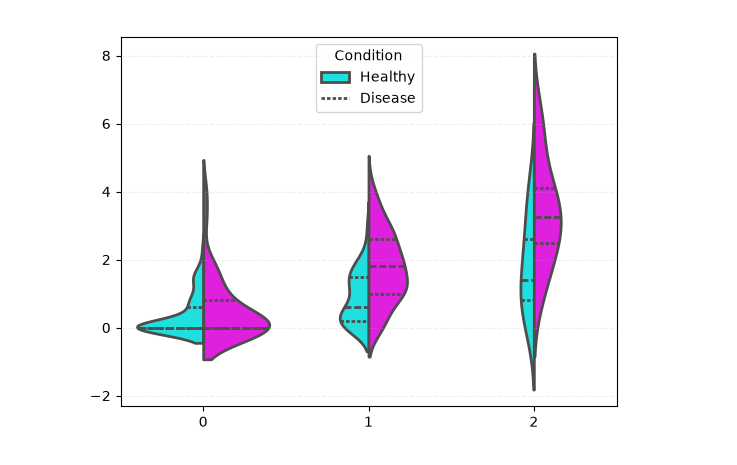

In [16]:
neon_palette = ['#00FFFF', '#FF00FF'] 
sns.set_palette(neon_palette)
sns.violinplot(data=df, x='slope', y='oldpeak', hue='condition', split=True, inner='quartile',   
linewidth=2, palette=neon_palette)
plt.title('Impact of ST Slope & Depression on Heart Disease', fontsize=18, color='white', weight='bold')
plt.xlabel('Slope Type (0=Up, 1=Flat, 2=Down)', fontsize=14, color='white')
plt.ylabel('ST Depression (Oldpeak)', fontsize=14, color='white')
plt.legend(title='Condition', labels=['Healthy', 'Disease'], loc='upper center')
plt.grid(axis='y', linestyle='--', alpha=0.2)

plt.show()

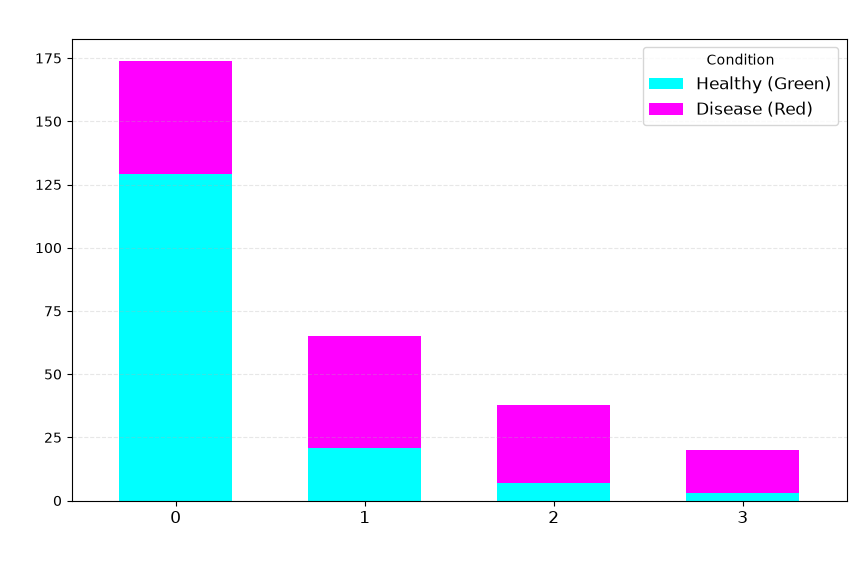

In [17]:
cross_data = pd.crosstab(df['ca'], df['condition'])
ax = cross_data.plot(kind='bar', stacked=True, figsize=(10, 6)
                     , width=0.6)
plt.title('Risk by Number of Major Vessels (ca)', fontsize=20, color='white', weight='bold')
plt.xlabel('Number of Colored Vessels (0-3)', fontsize=14, color='white')
plt.ylabel('Number of Patients', fontsize=14, color='white')
plt.xticks(rotation=0, fontsize=12)

plt.legend(title='Condition', labels=['Healthy (Green)', 'Disease (Red)'], 
           loc='upper right', fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

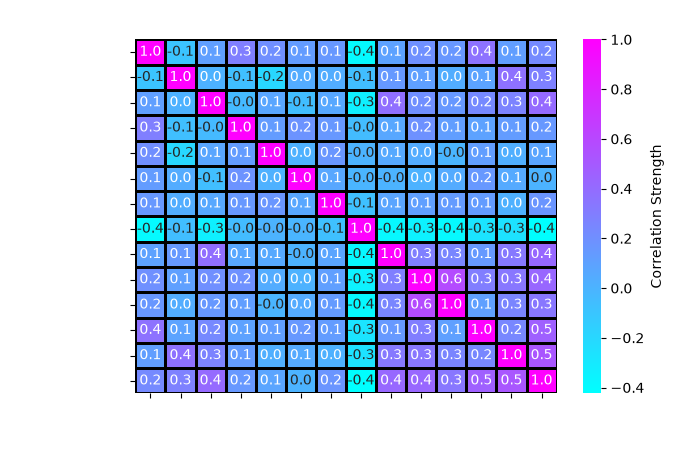

In [18]:
sns.heatmap(df.corr(), 
            annot=True, 
            fmt=".1f", 
            cmap='cool', 
            linewidths=1, 
            linecolor='black',
            cbar_kws={'label': 'Correlation Strength'})

plt.title('Correlation Heatmap (Heart Disease Data)', fontsize=20, color='white', weight='bold')
plt.xticks(rotation=45, color='white') 
plt.yticks(color='white')

plt.tight_layout()
plt.show()

In [19]:
target = "condition"
X = df.drop(columns=[target])
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

In [20]:
# Optional model comparison. lazypredict is NOT a runtime dependency, so skip it if it isn't installed.
try:
    from lazypredict.Supervised import LazyClassifier
    clf = LazyClassifier(verbose=0, ignore_warnings=True, custom_metric=None)
    models, predictions = clf.fit(X_train, X_test, y_train, y_test)
except ImportError:
    models = None
    print("lazypredict not installed - skipping model comparison (pip install lazypredict to run it)")

lazypredict not installed - skipping model comparison (pip install lazypredict to run it)


In [21]:
print(models)

None


In [22]:
# FIX: the scaler and the model are saved together as ONE Pipeline.
# Before, only the LogisticRegression was saved and the API fed it unscaled values (train/serve skew).
from sklearn.pipeline import Pipeline
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])
pipe.fit(X_train, y_train)
lr_pred = pipe.predict(X_test)
test_acc = accuracy_score(y_test, lr_pred)
print("Accuracy:", test_acc)
print(classification_report(y_test, lr_pred, target_names=["No Heart Disease", "Heart Disease"]))

Accuracy: 0.9166666666666666
                  precision    recall  f1-score   support

No Heart Disease       0.86      1.00      0.93        32
   Heart Disease       1.00      0.82      0.90        28

        accuracy                           0.92        60
       macro avg       0.93      0.91      0.91        60
    weighted avg       0.93      0.92      0.92        60



In [23]:
import joblib

In [24]:
joblib.dump(pipe, MODEL_DIR / "heart_model.joblib")
metadata = {
    "features": list(X.columns),
    "classes": {"0": "No Heart Disease", "1": "Heart Disease"},
    "target": target,
    "model": "StandardScaler + LogisticRegression",
    "test_accuracy": round(float(test_acc), 4),
    "sklearn_version": sklearn.__version__,
}
(MODEL_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))
print("Model saved to", MODEL_DIR / "heart_model.joblib")

Model saved to ..\model\heart_model.joblib
